# Radix sort

Ordena enteros dígito a dígito, del menos significativo al más significativo (LSD), con una ordenación estable por dígito (counting sort o cubetas). Como cada pasada es estable, el orden de los dígitos ya procesados se conserva. Con $d$ dígitos en base $b$ cuesta $O(d \, (n + b))$: lineal cuando $d$ es constante. No compara elementos, así que no está sujeto al límite $\Omega(n \log n)$.

## 1. Radix sort LSD en base 10

Implementar radix sort para enteros no negativos repartiendo en 10 cubetas por cada dígito, mostrar la lista tras cada pasada y comprobarlo contra `sorted`.

In [1]:
import random
import time

import matplotlib.pyplot as plt

def radix_sort(lista, base=10, traza=False):
    l = lista[:]
    if not l:
        return l
    exp = 1
    while max(l) // exp > 0:
        cubetas = [[] for _ in range(base)]
        for x in l:
            cubetas[x // exp % base].append(x)
        l = [x for cubeta in cubetas for x in cubeta]
        if traza:
            print(f"dígito {exp:>4}: {l}")
        exp *= base
    return l

radix_sort([170, 45, 75, 90, 802, 24, 2, 66], traza=True)

random.seed(1)
for _ in range(500):
    datos = [random.randint(0, 10**6) for _ in range(random.randint(0, 50))]
    assert radix_sort(datos) == sorted(datos)

dígito    1: [170, 90, 802, 2, 24, 45, 75, 66]
dígito   10: [802, 2, 24, 45, 66, 170, 75, 90]
dígito  100: [2, 24, 45, 66, 75, 90, 170, 802]


## 2. Negativos

Ampliar radix sort a enteros negativos: ordenar por separado los valores absolutos de los negativos y los no negativos y unir los negativos invertidos delante.

In [2]:
def radix_sort_enteros(lista):
    negativos = radix_sort([-x for x in lista if x < 0])
    positivos = radix_sort([x for x in lista if x >= 0])
    return [-x for x in reversed(negativos)] + positivos

print(radix_sort_enteros([5, -3, 0, -120, 77, -3, 12]))
for _ in range(500):
    datos = [random.randint(-10**5, 10**5) for _ in range(random.randint(0, 50))]
    assert radix_sort_enteros(datos) == sorted(datos)

[-120, -3, -3, 0, 5, 12, 77]


## 3. Cadenas de la misma longitud

Ordenar códigos postales o matrículas (cadenas de igual longitud) con radix sort carácter a carácter de derecha a izquierda, usando `ord` como dígito.

In [3]:
def radix_sort_cadenas(cadenas):
    l = cadenas[:]
    for pos in range(len(l[0]) - 1, -1, -1):
        cubetas = [[] for _ in range(128)]
        for c in l:
            cubetas[ord(c[pos])].append(c)
        l = [c for cubeta in cubetas for c in cubeta]
    return l

matriculas = ["4821KLM", "0007BBC", "9999ZZZ", "4821KLA", "1234XYZ", "0007BBB"]
print(radix_sort_cadenas(matriculas))
assert radix_sort_cadenas(matriculas) == sorted(matriculas)

['0007BBB', '0007BBC', '1234XYZ', '4821KLA', '4821KLM', '9999ZZZ']


## 4. Base y tiempo

Medir el tiempo de radix sort con bases 2, 10, 256 y 65536 para 300 000 enteros de 32 bits y compararlo con `sorted`. Una base mayor hace menos pasadas pero cada pasada maneja más cubetas.

base 2        0.96 s
base 10       0.34 s
base 256      0.17 s
base 65536    0.20 s
sorted        0.06 s


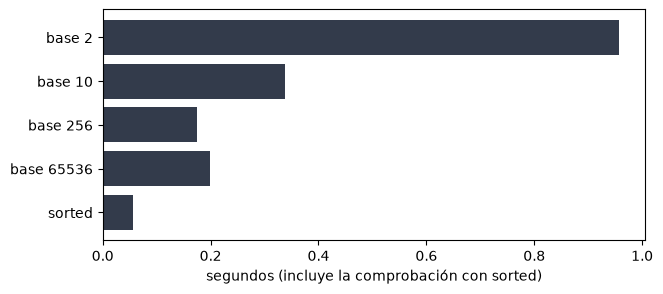

In [4]:
random.seed(2)
datos = [random.getrandbits(32) for _ in range(300_000)]
tiempos = {}
for base in (2, 10, 256, 65536):
    inicio = time.perf_counter()
    assert radix_sort(datos, base) == sorted(datos)
    tiempos[f"base {base}"] = time.perf_counter() - inicio
inicio = time.perf_counter()
sorted(datos)
tiempos["sorted"] = time.perf_counter() - inicio

for nombre, t in tiempos.items():
    print(f"{nombre:<12}{t:6.2f} s")
fig, eje = plt.subplots(figsize=(7, 3))
eje.barh(list(tiempos), list(tiempos.values()), color="#333b4b")
eje.invert_yaxis()
eje.set_xlabel("segundos (incluye la comprobación con sorted)")
plt.show()